# noisy: DINOv2 и геометрия

Используем уже сохранённые DINOv2 embeddings шести ракурсов. Сравниваем их с геометрией и прежней связкой на том же разбиении. Internal test не используем.

## 1. Данные

In [1]:
%pip install -q catboost iterative-stratification

from pathlib import Path
import hashlib
import io
import json
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from catboost import CatBoostClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data/train.csv').is_file()), None)
if ROOT is None:
    ROOT = Path('/content/drive/MyDrive/Colab Notebooks/colab_upload/AI challenge main')
assert (ROOT / 'data/train.csv').is_file(), ROOT

package = ROOT / 'noisy_dinov2_assets.zip'
if package.is_file():
    with zipfile.ZipFile(package) as archive:
        for name in archive.namelist():
            if not (ROOT / name).is_file():
                archive.extract(name, ROOT)

labels = pd.read_csv(ROOT / 'data/train.csv')
targets = labels.columns.drop('item_id').tolist()
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.15, random_state=42)
train_val_idx, test_idx = next(split.split(labels, labels[targets]))
train_val = labels.iloc[train_val_idx].reset_index(drop=True)
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.1765, random_state=43)
train_idx, val_idx = next(split.split(train_val, train_val[targets]))
train = train_val.iloc[train_idx].reset_index(drop=True)
val = train_val.iloc[val_idx].reset_index(drop=True)
objects = pd.concat([train, val], ignore_index=True)
assert (len(train), len(val), len(test_idx)) == (6259, 1361, 1344)
assert set(train.item_id).isdisjoint(val.item_id)
print('Train:', len(train), 'Validation:', len(val), '| noisy:', int(train.noisy.sum()), int(val.noisy.sum()))

Mounted at /content/drive
Train: 6259 Validation: 1361 | noisy: 1785 382


## 2. Готовые embeddings и геометрия

In [2]:
cache = ROOT / 'labels/simple/models/dinov2'
for name in ('embeddings.npy', 'embeddings_done.npy', 'embeddings_manifest.json'):
    assert (cache / name).is_file(), f'Нет {name}. Нужен готовый cache DINOv2 из опыта simple.'
manifest = json.loads((cache / 'embeddings_manifest.json').read_text(encoding='utf-8'))
assert manifest['model'] == 'dinov2_vits14'
assert manifest['item_ids'] == objects.item_id.tolist(), 'Порядок embeddings не совпадает с разбиением'
assert manifest['labels_sha256'] == hashlib.sha256((ROOT / 'data/train.csv').read_bytes()).hexdigest()
assert np.load(cache / 'embeddings_done.npy').all(), 'Embeddings извлечены не для всех объектов'
embeddings = np.load(cache / 'embeddings.npy', mmap_mode='r')
assert embeddings.shape == (7620, 6, 384)

config = json.loads((ROOT / 'archive/artifacts/catboost_features_config.json').read_text(encoding='utf-8'))
base_columns = config['feature_columns']
local_columns = ['pca_curvature_mean', 'pca_curvature_p90', 'pca_curvature_p95',
                 'normal_variation_p50', 'normal_variation_p90', 'normal_variation_p95',
                 'normal_variation_std', 'dihedral_over_10_share', 'dihedral_over_30_share']
base = pd.read_csv(ROOT / 'archive/artifacts/train_mesh_features_relative.csv').set_index('item_id')
local = pd.read_csv(ROOT / 'labels/lowpoly/artifacts/geometry_features.csv').set_index('item_id')
smooth = pd.read_csv(ROOT / 'labels/noisy/artifacts/smoothing_features.csv').set_index('item_id')
smooth_columns = [c for c in smooth if c.startswith('smooth_')]
assert len(base_columns) == 44 and len(local_columns) == 9 and len(smooth_columns) == 14
assert base.index.is_unique and local.index.is_unique and smooth.index.is_unique
assert not set(base_columns) & set(local_columns + smooth_columns)
geometry_columns = base_columns + local_columns + smooth_columns
geometry = base.join(local[local_columns]).join(smooth[smooth_columns])
assert set(objects.item_id).issubset(geometry.index)
geometry = geometry.loc[objects.item_id, geometry_columns].to_numpy(dtype=np.float32)
assert not np.isinf(geometry).any()

old = pd.read_csv(ROOT / 'labels/noisy/artifacts/old_fusion_validation.csv').set_index('item_id').loc[val.item_id]
geo = pd.read_csv(ROOT / 'labels/noisy/artifacts/validation_probabilities.csv').set_index('item_id').loc[val.item_id]
assert np.array_equal(old.noisy.to_numpy(), val.noisy.to_numpy())
assert np.array_equal(geo.noisy.to_numpy(), val.noisy.to_numpy())
print('Embeddings:', embeddings.shape, '| геометрия:', geometry.shape)

Embeddings: (7620, 6, 384) | геометрия: (7620, 67)


## 3. DINOv2 и CatBoost

In [3]:
views = np.asarray(embeddings)
mean = views.mean(axis=1)
mean_max = np.concatenate([mean, views.max(axis=1)], axis=1)
features = {
    'D1_mean': mean,
    'D2_mean_max': mean_max,
    'D3_mean_max_geometry': np.concatenate([mean_max, geometry], axis=1),
}
y_train = train.noisy.to_numpy()
y_val = val.noisy.to_numpy()
n_train = len(train)
grid = np.arange(.05, .96, .01)
out = ROOT / 'labels/noisy/models/dinov2'
out.mkdir(parents=True, exist_ok=True)

def evaluate(p, threshold):
    pred = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    return {'Precision': precision_score(y_val, pred, zero_division=0),
            'Recall': recall_score(y_val, pred, zero_division=0),
            'F1': f1_score(y_val, pred, zero_division=0),
            'AP': average_precision_score(y_val, p),
            'FP': int(fp), 'FN': int(fn), 'Threshold': float(threshold)}

results = [
    {'Experiment': 'Old ResNet18 + CatBoost', **evaluate(old.fusion.to_numpy(), .47)},
    {'Experiment': 'E4 geometry', **evaluate(geo.E4_all.to_numpy(), .34)},
]
probabilities = val[['item_id', 'noisy']].copy()
probabilities['Old_fusion'] = old.fusion.to_numpy()
probabilities['E4_geometry'] = geo.E4_all.to_numpy()

for name, X in features.items():
    model = CatBoostClassifier(**config['parameters'])
    model.fit(X[:n_train], y_train, eval_set=(X[n_train:], y_val),
              early_stopping_rounds=50, verbose=False)
    p = model.predict_proba(X[n_train:])[:, 1]
    threshold = float(max(grid, key=lambda t: f1_score(y_val, p >= t)))
    results.append({'Experiment': name, **evaluate(p, threshold)})
    probabilities[name] = p
    model.save_model(str(out / f'{name}.cbm'))
    print(name, '| F1:', round(results[-1]['F1'], 4), '| AP:', round(results[-1]['AP'], 4), flush=True)

D1_mean | F1: 0.8047 | AP: 0.8734
D2_mean_max | F1: 0.8065 | AP: 0.8776
D3_mean_max_geometry | F1: 0.8301 | AP: 0.8903


## 4. Смешивание вероятностей

In [4]:
for reference in ('E4_geometry', 'Old_fusion'):
    for weight in (.25, .50, .75):
        p = weight * probabilities.D2_mean_max.to_numpy() + (1 - weight) * probabilities[reference].to_numpy()
        threshold = float(max(grid, key=lambda t: f1_score(y_val, p >= t)))
        name = f'D2 + {reference} ({weight:.2f} DINO)'
        results.append({'Experiment': name, **evaluate(p, threshold)})
        probabilities[name] = p

table = pd.DataFrame(results).sort_values('F1', ascending=False)
display(table.round(4))
table.to_csv(out / 'metrics.csv', index=False)
probabilities.to_csv(out / 'validation_probabilities.csv', index=False)
print('Сохранено:', out)

,Experiment,Precision,Recall,F1,AP,FP,FN,Threshold
4,D3_mean_max_geometry,0.8105,0.8508,0.8301,0.8903,76,57,0.35
6,D2 + E4_geometry (0.50 DINO),0.7895,0.8639,0.8250,0.8957,88,52,0.34
9,D2 + Old_fusion (0.50 DINO),0.7880,0.8560,0.8206,0.8884,88,55,0.41
7,D2 + E4_geometry (0.75 DINO),0.8223,0.8115,0.8169,0.8926,67,72,0.43
5,D2 + E4_geometry (0.25 DINO),0.8375,0.7958,0.8161,0.8885,59,78,0.47
8,D2 + Old_fusion (0.25 DINO),0.7921,0.8377,0.8142,0.8835,84,62,0.45
10,D2 + Old_fusion (0.75 DINO),0.7840,0.8455,0.8136,0.8863,89,59,0.38
3,D2_mean_max,0.7665,0.8508,0.8065,0.8776,99,57,0.34
0,Old ResNet18 + CatBoost,0.7722,0.8429,0.8060,0.8658,95,60,0.47
2,D1_mean,0.8112,0.7984,0.8047,0.8734,71,77,0.47


Сохранено: /content/drive/MyDrive/Colab Notebooks/colab_upload/AI challenge main/labels/noisy/models/dinov2


## 5. Ошибки

noisy + lowpoly: 12 объектов, 7 пропущено
noisy + artifacts: 24 объектов, 5 пропущено


,item_id,noisy,lowpoly,artifacts,probability,prediction
1206,e45ee341-3dfd-4836-b7a8-8b6ac59cc858,0,0,1,0.988797,1
941,b00334f0-9d59-47bc-b28c-305f257e32f0,0,0,1,0.985603,1


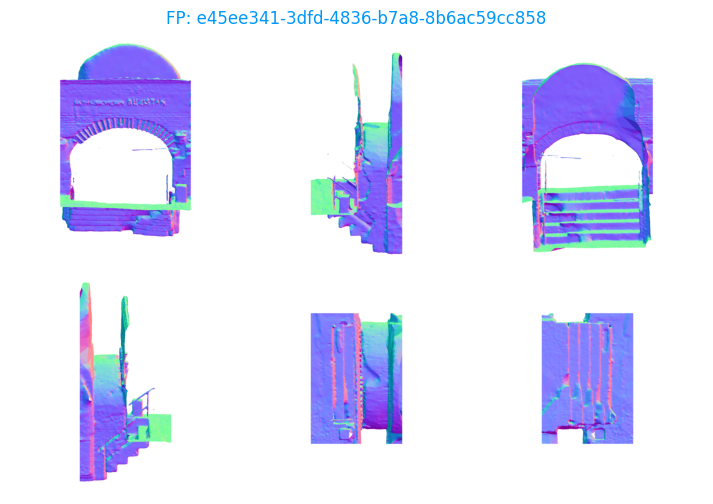

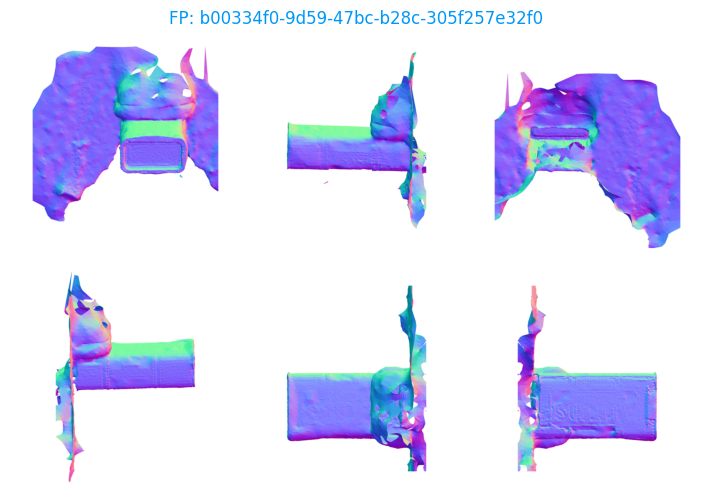

,item_id,noisy,lowpoly,artifacts,probability,prediction
243,2ed48369-64ec-4152-afc4-1fe510e68a5a,1,0,0,0.008232,0
841,9ee63aa5-7324-44e6-9efd-e05713cc4ee0,1,0,0,0.013213,0


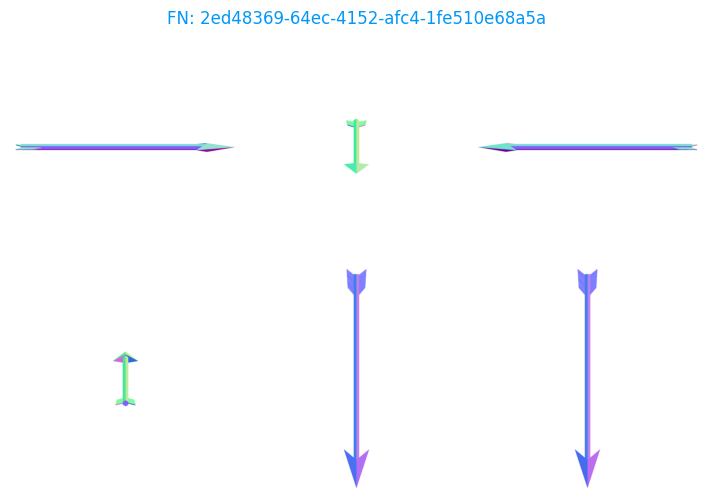

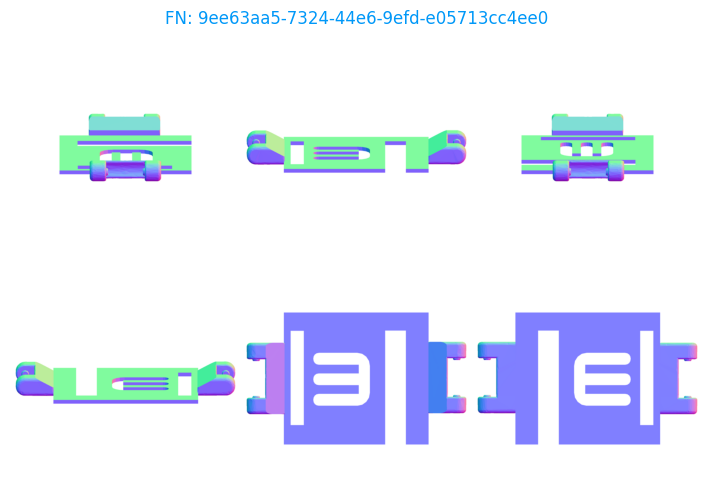

In [5]:
best = table.iloc[0]
column = {'Old ResNet18 + CatBoost': 'Old_fusion', 'E4 geometry': 'E4_geometry'}.get(best.Experiment, best.Experiment)
review = val[['item_id', 'noisy', 'lowpoly', 'artifacts']].copy()
review['probability'] = probabilities[column].to_numpy()
review['prediction'] = (review.probability >= best.Threshold).astype(int)
for label in ('lowpoly', 'artifacts'):
    group = review[(review.noisy == 1) & (review[label] == 1)]
    print(f'noisy + {label}: {len(group)} объектов, {int((group.prediction == 0).sum())} пропущено')

png_dir = ROOT / 'data/train'
png_zip = ROOT / 'data/train_png.zip'
for title, frame in [('FP', review.query('noisy == 0 and prediction == 1')),
                     ('FN', review.query('noisy == 1 and prediction == 0'))]:
    sample = frame.sort_values('probability', ascending=title == 'FN').head(2)
    display(sample)
    for item_id in sample.item_id:
        if (png_dir / f'{item_id}.png').is_file():
            image = Image.open(png_dir / f'{item_id}.png')
        elif png_zip.is_file():
            with zipfile.ZipFile(png_zip) as archive:
                name = next(name for name in archive.namelist() if name.endswith(f'{item_id}.png'))
                image = Image.open(io.BytesIO(archive.read(name)))
        else:
            print('PNG не найден:', item_id)
            continue
        plt.figure(figsize=(12, 6))
        plt.imshow(image.convert('RGB'))
        plt.title(f'{title}: {item_id}', color='#0098F8')
        plt.axis('off')
        plt.show()
        image.close()

## Вывод

Сравниваем лучший F1 с прежней связкой 0.8060 и вариантом геометрии 0.8025. Все модели и пороги выбраны по одной validation, поэтому оценка может быть оптимистичной. Internal test не используется.